# D5 – Mini-projet : une série temporelle

**Python numérique – devoir n° 5 – à rendre pour le dimanche 18 octobre 2026, 23 h 59** (la séance 6 est le mardi 20)

Bienvenue dans votre cinquième devoir ! Nous allons y mettre en œuvre les notions vues en séance 5 : `to_datetime`, `DatetimeIndex`, la sélection par dates, `resample`, `rolling`, `df.plot` et les figures à plusieurs sous-graphiques avec `matplotlib`. C'est aussi un mini-projet : la dernière partie est ouverte, et c'est vous qui choisissez la question à laquelle répondre.

Durée indicative : 1 h 30.

````{admonition} Consignes de rendu
:class: important

* Ce notebook reste dans le dossier `D5/` de votre dépôt `pe-homework` (celui que le zip du sujet a créé en se dézippant), avec ses figures à côté, puis il doit être **commité et poussé** (`git add`, `git commit`, `git push`) avant la deadline. Attention, c'est la **date du commit** qui fait foi, pas celle du push ; le nom du fichier, lui, n'a pas d'importance (`sujet.ipynb` convient très bien). Le dossier `data/` livré avec le sujet reste lui aussi dans `D5/` : `git add D5` embarque tout le dossier, et c'est très bien ainsi (il ne pèse que quelques kilo-octets).
* Juste avant de rendre, **pensez à ré-exécuter toutes les cellules** via *Kernel → Restart Kernel and Run All Cells* : toutes doivent s'exécuter dans l'ordre et sans erreur. En effet, un notebook qui plante à mi-chemin sera corrigé jusqu'à l'erreur…
* Le notebook lit les données dans `data/comptage-velos.csv` (chemin relatif) ; la figure `serie.png` est quant à elle écrite dans le dossier du notebook.
* Les cellules `# votre code` sont à compléter ; vous pouvez ajouter autant de cellules que vous le souhaitez. Les cellules de test (`assert`) sont là pour vous aider : si elles passent sans erreur, c'est bon signe. Ne les modifiez pas !
* Répondez aux questions "en français" dans une cellule *Markdown*, en deux ou trois phrases. Dans ce devoir, la rédaction compte autant que le code.
````

````{admonition} Ce qui est autorisé
:class: note

* La documentation de `pandas` / `matplotlib`, les notebooks du cours, vos notes.
* Les assistants IA sont tolérés, avec la règle habituelle : **vous devez être capable d'expliquer chaque ligne que vous rendez**, et je pourrai vous demander de le faire à l'oral en séance. Le devoir est individuel.
* En revanche, pas de boucle `for` sur les lignes de la série : tout se fait avec les opérations `pandas`.
````

````{admonition} Les données
:class: warning

`data/comptage-velos.csv` contient le nombre de vélos comptés chaque jour par un compteur automatique installé sur une piste cyclable parisienne, du 1er janvier 2023 au 31 décembre 2024 : une colonne `date` (texte `AAAA-MM-JJ`) et une colonne `comptage`, séparées par `;`.

Attention, **ces données sont simulées** : je les ai produites avec le script `data/generate.py`, en fixant la graine afin que tout le monde travaille sur les mêmes valeurs. Vous pouvez le lire, mais seulement *après* avoir fait le devoir ! Elles ont cependant l'allure de vraies données de comptage, défauts compris : le fichier n'est pas trié, certaines lignes sont en double, certains jours n'ont pas de mesure, et le capteur a eu au moins deux ratés. Ainsi, comme dans la vraie vie, vous allez d'abord nettoyer, puis analyser.
````

## Barème

| Exercice | Contenu | Points |
|---|---|---|
| 1 | Chargement, index temporel, diagnostic et nettoyage | 6 |
| 2 | Rééchantillonnage (`resample`) et lissage (`rolling`) | 4 |
| 3 | Profils hebdomadaire et mensuel, 2023 vs 2024 | 4 |
| 4 | Figure à deux sous-graphiques `serie.png` | 3 |
| 5 | Question ouverte : une question, une figure, trois lignes de conclusion | 3 |
| **Total** | | **20** |
| Bonus | Jour le plus creux, croissance annuelle | +2 |

*Inspiré des exercices de <https://numerique-exos.info-mines.paris>.*

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Exercice 1 – Charger, indexer, nettoyer (6 pts)

**1.a** Lisez le fichier dans une `DataFrame` `df` et affichez `df.info()`. Quel est le type de la colonne `date` ? Pourquoi n'est-ce pas satisfaisant ? Le fichier est-il trié par date ?

In [2]:
# votre code
df = pd.read_csv("data/comptage-velos.csv", sep=";")
df.info()
df

<class 'pandas.DataFrame'>
RangeIndex: 734 entries, 0 to 733
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   date      734 non-null    str    
 1   comptage  726 non-null    float64
dtypes: float64(1), str(1)
memory usage: 11.6 KB


,date,comptage
0,2023-01-01,304.0
1,2023-01-02,1658.0
2,2023-01-03,1450.0
3,2023-01-04,1902.0
4,2023-01-05,1715.0
...,...,...
729,2024-12-30,1900.0
730,2024-12-31,2126.0
731,2023-12-21,1960.0
732,2023-05-25,3101.0


Le type de la colonne "date" est le string. Cela est embêtant car si par exemple on veut trier par date notre tableau cela sera fait par ordre alphabétique et nan par ordre chronologique. On voit bien qu'ici le fichier n'est pas trié par date.

In [3]:
assert df.shape == (734, 2)
assert list(df.columns) == ["date", "comptage"]
print("ok")

ok


**1.b** Construisez maintenant la `Series` `brut` : les comptages indexés par la date, avec un vrai `DatetimeIndex`, triée par date et en flottants.

In [4]:
# votre code
df["date"] = pd.to_datetime(df["date"],format= "%Y-%m-%d")
df = df.set_index("date").sort_index()
brut = df["comptage"] 

In [5]:
assert isinstance(brut, pd.Series)
assert isinstance(brut.index, pd.DatetimeIndex)
assert brut.index.is_monotonic_increasing
assert len(brut) == 734
assert brut.index[0] == pd.Timestamp("2023-01-01") and brut.index[-1] == pd.Timestamp("2024-12-31")
print("ok")

ok


````{admonition} Pas encore vu en cours : duplicated()
:class: note

`serie.duplicated()` — ou `index.duplicated()` — renvoie un tableau de booléens de même longueur, avec `True` sur les valeurs *déjà rencontrées plus haut* : la première occurrence vaut `False`, les suivantes `True`. Ainsi, sur `[3, 1, 3, 3]`, on obtient `[False, False, True, True]`. Combiné à `~`, il permet donc de ne garder que la première occurrence de chaque valeur.
````

**1.c** Place au diagnostic. Répondez d'abord par du code, puis résumez vos observations dans une cellule Markdown :

* combien de dates apparaissent en double ? lesquelles ?
* combien de valeurs manquantes ? quels jours ?
* observez `brut.describe()` : le minimum et le maximum vous semblent-ils plausibles pour un compteur vélo ? Affichez les jours dont le comptage est nul, et ceux dont le comptage dépasse 3 fois la médiane.

In [6]:
# votre code
double = df.index.duplicated()
df[double]

,comptage
date,
2023-05-25,3101.0
2023-12-21,1960.0
2024-02-27,2622.0


Trois dates apparaissent en double, il s'agit du 25 mai 2023, du 21 décembre 2023 et du 27 février 2024.

In [7]:
manquant = df["comptage"].isna()
df[manquant]

,comptage
date,
2023-02-23,NaN
2023-06-25,NaN
2023-12-01,NaN
2024-01-09,NaN
2024-02-08,NaN
2024-03-13,NaN
2024-11-17,NaN
2024-11-22,NaN


Il manque 8 valeurs, pour les 23 février 2023, 25 juin 2023, 1er décembre 2023, 9 janvier 2024, 8 février 2024, 13 mars 2024, 17 novembre 2024 et 22 novembre 2024

In [8]:
brut.describe()
df[df["comptage"]==0]

,comptage
date,
2024-06-27,0.0


In [9]:
df[df["comptage"]>= 3*df["comptage"].median()]

,comptage
date,
2024-07-04,39660.0


Nous avons du mal à croire en ces extrema. En effet, que pas un seul vélo ne soit passé durant une journée, celle du 27 juin 2024, est peu plausible, comme il y a très peu de chance que 39660 vélos soient passés sur le seul jour du 4 juillet 2024.

In [10]:
assert brut.index.duplicated().sum() == 3
assert brut.isna().sum() == 8
assert (brut == 0).sum() == 1
assert (brut > 3 * brut.median()).sum() == 1
print("ok")

ok


````{admonition} Pas encore vu en cours : interpolate()
:class: note

`serie.interpolate()` remplace chaque `NaN` par une valeur déduite de ses voisins non manquants, par interpolation linéaire par défaut : sur `[10, NaN, NaN, 40]`, on obtient `[10, 20, 30, 40]`. C'est l'alternative à `fillna` quand les données ont un ordre naturel, comme ici le temps.
````

**1.d** Passons au nettoyage. Construisez la série propre `velos`, en trois temps :

1. supprimez les doublons d'index en ne gardant que la première occurrence (`duplicated()`) ;
2. remplacez les deux valeurs aberrantes (comptage nul ou supérieur à 3 fois la médiane) par `NaN` ;
3. remplissez tous les `NaN` (les 8 jours vides + les 2 aberrants) par interpolation linéaire.

Vérifiez enfin que `velos` a exactement une valeur par jour du 1er janvier 2023 au 31 décembre 2024 (soit 731 jours), et plus aucun `NaN`.

In [11]:
# votre code
velos = brut[~double]
velos.loc["2024-06-27"] = np.nan
velos.loc["2024-07-04"] = np.nan
velos = velos.interpolate()
(~velos.isna()).sum()

np.int64(731)

In [12]:
assert len(velos) == 731
assert velos.isna().sum() == 0
assert not velos.index.duplicated().any()
assert (velos.index == pd.date_range("2023-01-01", "2024-12-31", freq="D")).all()
assert velos.min() > 100 and velos.max() < 6000
assert abs(velos.loc["2024-07-04"] - (velos.loc["2024-07-03"] + velos.loc["2024-07-05"]) / 2) < 1
print("ok")

ok


## Exercice 2 – Rééchantillonner et lisser (4 pts)

**2.a** Calculez :

* `hebdo` : la moyenne par semaine ;
* `mensuel` : la moyenne par mois (l'alias de fréquence des mois est `"ME"`, *month end*, depuis pandas 2.2 ; `"M"` si votre pandas est plus ancien) ;
* `annuel` : le **total** par année.

Combien de lignes ont `hebdo` et `mensuel` ? Pourquoi `hebdo` n'a-t-il pas exactement 731 / 7 lignes ?

In [13]:
# votre code
hebdo = velos.resample("W").mean()
mensuel = velos.resample("ME").mean()
annuel = velos.resample("YE").sum()
print(hebdo.shape , mensuel.shape)

(106,) (24,)


hebdo n'a pas 105 lignes (on arrondi 731/7 au supérieur) mais 106 lignes car le resample s'arrête à la fin de chaque année, ce qui sépare donc des semaines.

In [14]:
assert len(hebdo) == 106 and len(mensuel) == 24 and len(annuel) == 2
assert abs(mensuel.sum() * 30.4 - velos.sum()) / velos.sum() < 0.05
assert annuel.iloc[1] > annuel.iloc[0]
print("ok")

ok


**2.b** Calculez `lisse`, la moyenne glissante **centrée** sur 7 jours. Combien de `NaN` contient-elle, et où ? Pourquoi 7 jours est-il un bon choix de fenêtre pour cette série ? Enfin, tracez `velos` (trait fin, transparent) et `lisse` sur le même graphique, avec la méthode `.plot()` des `Series`.

In [15]:
# votre code
lisse = velos.rolling(7,center = True).mean()
lisse[lisse.isna()]

date
2023-01-01   NaN
2023-01-02   NaN
2023-01-03   NaN
2024-12-29   NaN
2024-12-30   NaN
2024-12-31   NaN
Name: comptage, dtype: float64

Lisse contient 6 NaN les 3 premiers et derniers jours de l'index car pour calculer le rolling sur 7 jours, rolling a besoin des 3 valeurs précédentes et suivantes, ce qui n'est possible qu'à partir du 4e jour. 7 jours est un bon choix car les évolutions de la pratique du vélo se font principalment selon les semaines plus que selon les mois, du fait de l'influence de la météo par exemple.

In [16]:
assert len(lisse) == 731
assert lisse.isna().sum() == 6
assert abs(lisse.loc["2023-06-15"] - velos.loc["2023-06-12":"2023-06-18"].mean()) < 1e-9
print("ok")

ok


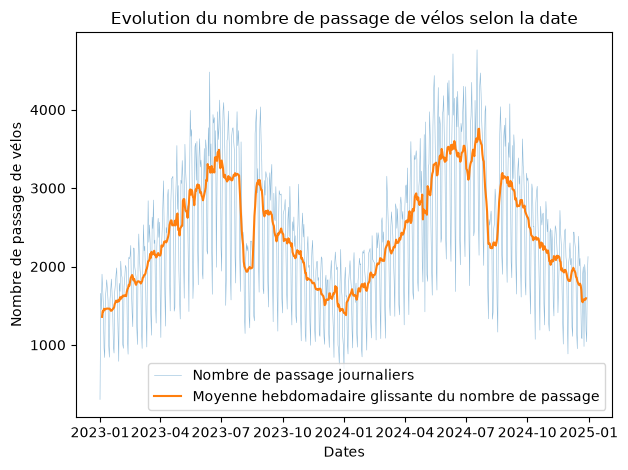

In [17]:
fig, ax = plt.subplots()
ax.plot(velos, alpha=0.5, lw=0.4, label="Nombre de passage journaliers")
ax.plot(lisse, label="Moyenne hebdomadaire glissante du nombre de passage")
ax.set_ylabel("Nombre de passage de vélos")
ax.set_xlabel("Dates")
ax.legend()
ax.set_title("Evolution du nombre de passage de vélos selon la date")
plt.tight_layout()
plt.show()



## Exercice 3 – Profils (4 pts)

**3.a** Commençons par le profil hebdomadaire : calculez `profil_semaine`, la moyenne des comptages pour chaque jour de la semaine, avec 0 = lundi … 6 = dimanche. Remplacez ensuite l'index `0..6` par les noms des jours (`"lun"`, `"mar"`, … `"dim"`). De combien (en %) le dimanche est-il plus bas que la moyenne des jours de semaine (lundi à vendredi) ?

In [18]:
# votre code
profil_semaine = (velos.to_frame(name="comptage")).groupby(velos.index.dayofweek)["comptage"].mean()
profil_semaine.index = ["lun","mar","mer","jeu","ven","sam","dim"]
profil_semaine

lun    2694.095238
mar    2868.504762
mer    2877.658654
jeu    2782.269231
ven    2595.394231
sam    1639.942308
dim    1386.380952
Name: comptage, dtype: float64

In [19]:
(profil_semaine.loc["lun":"ven"].mean()-profil_semaine.loc["dim"])/profil_semaine.loc["lun":"ven"].mean()*100

np.float64(49.83395691464415)

Le dimanche a une valeur moyenne de passage près de 49,83 % (soit presque de moitié) inférieur à la moyenne des jours de la semaine.

In [20]:
assert profil_semaine.shape == (7,)
assert list(profil_semaine.index) == ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
assert profil_semaine["sam"] < 0.75 * profil_semaine["lun"]
assert profil_semaine["dim"] < profil_semaine["sam"]
print("ok")

ok


````{admonition} Pas encore vu en cours : idxmax et idxmin
:class: note

`serie.idxmax()` renvoie l'**étiquette** de la plus grande valeur (ici un numéro de mois), alors que `serie.max()` renvoie la valeur elle-même ; `idxmin` fait de même pour la plus petite. Sur une série indexée par des dates, on récupère donc directement le `Timestamp` du maximum.
````

**3.b** Intéressons-nous maintenant à la saisonnalité : calculez `profil_mois`, la moyenne pour chaque mois de l'année (1 à 12), les deux années confondues. Quel est le mois le plus chargé ? Et que se passe-t-il en août ?

In [21]:
# votre code
profil_mois = (velos.to_frame(name="comptage")).groupby(velos.index.month)["comptage"].mean()
profil_mois.idxmax()

np.int32(6)

Le mois le plus chargé est le mois de juin. En aout on observe une forte baisse abrupte par rapport au mois de juillet, passant d'environ 3285 passages à 2535, avant que la moyenne remonte en septembre. Cela peut sans doute s'expliquer par le départ en vacances des habitants (en juillet) suivi de la rentrée (en septembre) par exemple 

In [22]:
profil_mois

date
1     1547.806452
2     1845.000000
3     2144.024194
4     2585.300000
5     3013.000000
6     3313.183333
7     3285.483871
8     2535.774194
9     2693.766667
10    2309.419355
11    1924.308333
12    1657.911290
Name: comptage, dtype: float64

In [23]:
assert profil_mois.shape == (12,) and list(profil_mois.index) == list(range(1, 13))
assert profil_mois.idxmax() in (6, 7)
assert profil_mois[8] < profil_mois[7] and profil_mois[8] < profil_mois[9]
assert profil_mois.idxmin() in (1, 12)
print("ok")

ok


**3.c** Opposons enfin 2023 à 2024 : avec la sélection par chaîne de date, calculez la moyenne journalière de chaque année, puis la croissance en % de 2023 à 2024 (variable `croissance`). Posez-vous ensuite la même question mois par mois : construisez la table `par_mois` de forme `(12, 2)` (lignes = mois, colonnes = années) — `unstack` peut aider — et repérez le mois où la progression a été la plus forte.

In [24]:
# votre code
moyenne_annuelle = (velos.resample("YE").mean()).to_frame()
moyenne_annuelle.index=["2023","2024"]
moyenne_annuelle
croissance = ((moyenne_annuelle.loc["2024"]-moyenne_annuelle.loc["2023"])/moyenne_annuelle.loc["2023"]*100).to_numpy()
croissance

array([10.4816138])

In [25]:
par_mois = (velos.to_frame()).groupby([velos.index.month,velos.index.year]).mean()
par_mois = par_mois.unstack()
par_mois.columns = par_mois.columns.droplevel(0)
par_mois

date,2023,2024
date,,
1,1451.612903,1644.000000
2,1755.160714,1931.741379
3,2053.516129,2234.532258
4,2393.466667,2777.133333
5,2849.903226,3176.096774
6,3223.133333,3403.233333
7,3091.870968,3479.096774
8,2454.193548,2617.354839
9,2537.033333,2850.500000


In [26]:
assert 7 < croissance < 14
assert par_mois.shape == (12, 2)
assert list(par_mois.columns) == [2023, 2024]
assert (par_mois[2024] > par_mois[2023]).sum() >= 10
print("ok")

ok


## Exercice 4 – Figure à deux sous-graphiques (3 pts)

Construisez une figure `fig, (ax_haut, ax_bas) = plt.subplots(2, 1, figsize=(11, 8))` :

* en haut : la série journalière `velos` (trait fin, transparent) et la série lissée `lisse` (trait plus épais), avec une légende, un titre et un nom d'axe des ordonnées ;
* en bas : le profil hebdomadaire `profil_semaine` en barres, avec un titre et un nom d'axe des ordonnées.

Terminez par `fig.tight_layout()` et enregistrez dans `serie.png` (`fig.savefig`).

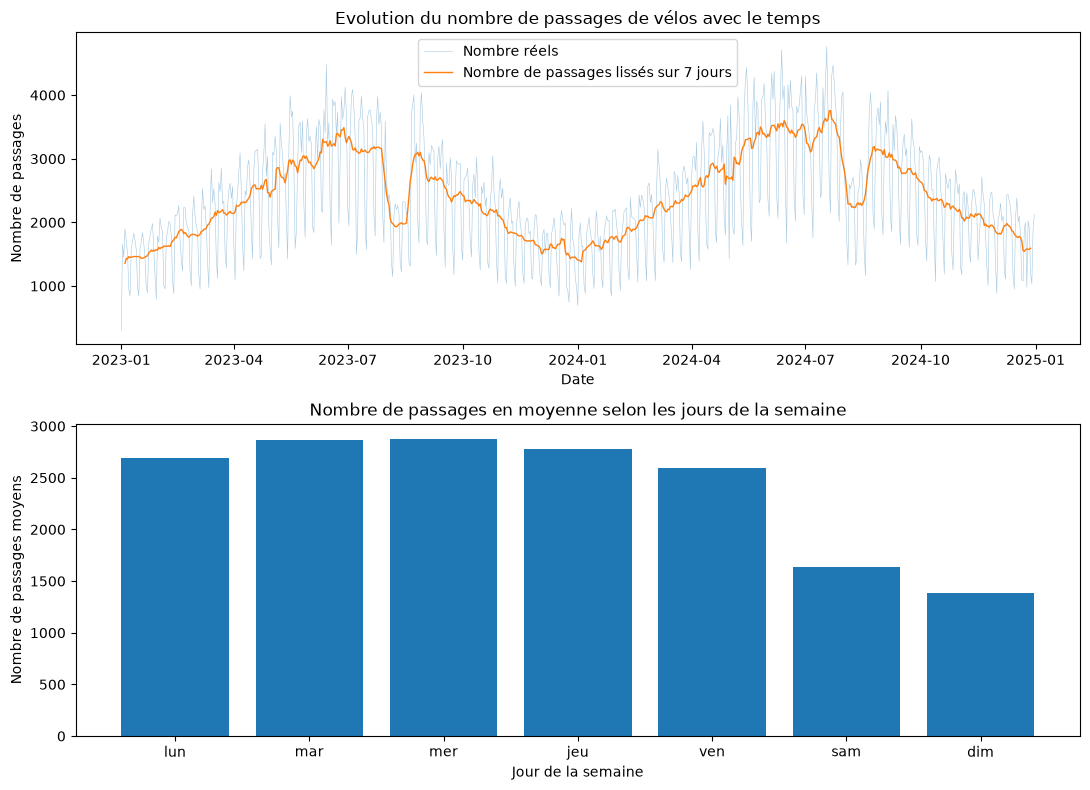

In [27]:
# votre code
fig, (ax_haut, ax_bas) = plt.subplots(2, 1, figsize=(11, 8))
ax_haut.plot(velos, alpha = 0.4, lw=0.4, label = "Nombre réels")
ax_haut.plot(lisse, lw=1, label = "Nombre de passages lissés sur 7 jours")
ax_haut.set_ylabel("Nombre de passages")
ax_haut.set_xlabel("Date")
ax_haut.legend()
ax_haut.set_title("Evolution du nombre de passages de vélos avec le temps")
ax_bas.bar(profil_semaine.index,profil_semaine.values)
ax_bas.set_ylabel("Nombre de passages moyens")
ax_bas.set_xlabel("Jour de la semaine")
ax_bas.set_title("Nombre de passages en moyenne selon les jours de la semaine")
fig.tight_layout()
fig.savefig("serie.png")
plt.show()


In [28]:
assert os.path.exists("serie.png")
print("ok")

ok


## Exercice 5 – Question ouverte (3 pts)

C'est ici que vous prenez la main ! Choisissez **une** question sur cette série, puis répondez-y avec une figure (au moins une courbe ou un diagramme, légendée et titrée) et trois lignes de conclusion en Markdown. Voici quelques idées, mais une question à vous est la bienvenue :

* le creux d'août a-t-il la même ampleur en 2023 et en 2024 ?
* l'écart week-end / semaine est-il le même en été et en hiver ?
* quelle semaine de l'année est la plus chargée ? la plus creuse ? est-ce la même les deux années ?
* la croissance entre 2023 et 2024 est-elle uniforme sur l'année, ou concentrée sur certains mois ?
* que se passe-t-il autour des jours fériés que vous connaissez ?

Côté barème, je compte un point pour la pertinence de la méthode, un point pour une figure lisible et correcte, et un point pour une conclusion chiffrée et honnête.

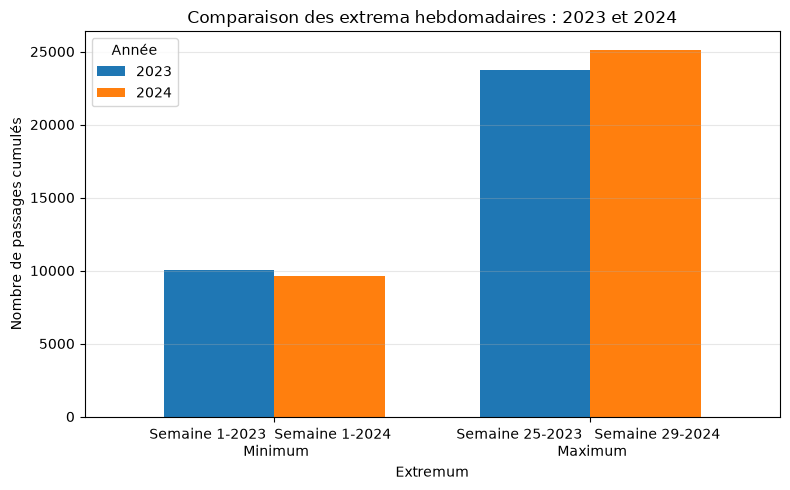

In [29]:
# votre code
dates = velos.index.isocalendar()
n_table = pd.DataFrame({
    "annee": dates.year.to_numpy(),
    "semaine": dates.week.to_numpy(),
    "velos": velos.to_numpy()})
n_hebdo = n_table.groupby(["annee", "semaine"])["velos"].sum()
extrema = n_hebdo.groupby(level="annee").agg(["min", "max"])
extrema = extrema.drop(index=2022)
extrema = extrema.drop(index=2025)
ax = extrema.T.plot(kind="bar", figsize=(8, 5), width=0.7)
ax.set_title("Comparaison des extrema hebdomadaires : 2023 et 2024")
ax.set_xlabel("Extremum")
ax.set_ylabel("Nombre de passages cumulés")
ax.set_xticklabels(["Semaine 1-2023  Semaine 1-2024  \n Minimum", "Semaine 25-2023   Semaine 29-2024 \n Maximum"], rotation=0)
ax.legend(title="Année")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


Les semaines les plus creuses sont la même en 2023 et en 2024, il s'agit de la première semaine de l'année avec sensiblement les mêmes valeurs. Quant aux maxima, il s'agit de la semaine 25 en 2023 et 29 en 2024 avec une valeur légèremement supérieure en 2024

## Bonus (+2)

**Bo.1** Quel est le jour le plus creux de toute la série ? Et le plus chargé ? Pour chacun, donnez le jour de la semaine (`.day_name()`) et proposez une explication.

````{admonition} Pas encore vu en cours : pct_change
:class: note

`serie.pct_change()` renvoie la variation *relative* d'une valeur à la suivante : sur `[100, 110, 99]`, elle donne `[NaN, 0.10, -0.10]`. La première case vaut `NaN` faute de valeur précédente, et le résultat est une proportion, à multiplier par 100 pour l'exprimer en pourcentage.
````

**Bo.2** Calculez la croissance annuelle en % à partir des totaux annuels `annuel`. Pourquoi ce chiffre est-il légèrement différent de `croissance` (exercice 3.c) ?

In [30]:
# votre code
print(velos.idxmax(),velos.idxmax().day_name(),velos.idxmin(),velos.idxmin().day_name()
     )


2024-07-18 00:00:00 Thursday 2023-01-01 00:00:00 Sunday


Le jour le plus creux est le 1er janvier 2023, pas étonnant vu qu'il s'agit du Nouvel an et la Saint-Sylvestre est un jour férié donc un jour où les gens restent chez eux, ne vont pas au travail et/ou récupèrent des excés de la veille, donc ne prennent pas le vélo. D'autant plus qu'il s'agit d'un dimanche, jour avec une activité réduite de base.
Le jour le plus chargé est le 18 juillet 2024. Cette activité peut s'expliquer par le bon temps en été qui favorise le vélo (surtout qu'en période de Tour de France tout le monde se met au vélo). A cela il faut rajouter qu'il s'agit d'un vendredi en période de vancances scolaires donc un jour avec une grande effervescence notamment le soir.

In [31]:
n_croissance = ((annuel.iloc[1]-annuel.iloc[0])/annuel.iloc[0]*100)
print(n_croissance,croissance[0])

10.78430315058774 10.481613797717293


La différence vient du fait que le pourcentage de croissance a été calculée sur les moyennes annuelles dans le cas de "croissance" et pas sur le nombre total de passages annuels comme pour "n_croissance"

Bon courage à tous ! Pour toute question sur le sujet, vous pouvez me contacter par email : [raphael@imagine-app.fr](mailto:raphael@imagine-app.fr).

Au plaisir de vous lire,

votre responsable de cours, Raphael Prasquier
(sujet conçu par Aurélien Noce)